DISCLAIMER: The dataset for this project is very large , so I have set the runtime to 'G4 GPU' in google colab. This project is done in Google colab.

** For running this full project set the runtime to 'G4 GPU' in google colab

In [1]:
!pip install -q lightgbm prophet darts pytorch-forecasting ortools dash dash-bootstrap-components

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error,mean_absolute_error
from prophet import Prophet
import lightgbm as lgb
import torch
from pytorch_forecasting import TimeSeriesDataSet, TemporalFusionTransformer
from pytorch_forecasting.metrics import QuantileLoss
import lightning.pytorch as pl
from lightning.pytorch import Trainer
import darts
from darts import TimeSeries
from darts.models import NaiveSeasonal
from darts.dataprocessing.transformers import BottomUpReconciliator
from ortools.linear_solver import pywraplp
import joblib

DATA INGESTION

In [3]:
# For refering the dataset - https://www.kaggle.com/competitions/m5-forecasting-accuracy/data
# Loading all the 3 files
print("Loading sales data (restricted to one state to save RAM)...")

# OPTION A: Reading only rows where state_id is 'CA' (California) to save memory
sales_df = pd.read_csv('sales_train_evaluation.csv', on_bad_lines= 'skip')

# Filtering for just one store first (e.g., 'CA_1') to keep things lightweight while building code
sales_df = sales_df[sales_df['store_id'] == 'CA_1']

calendar_df = pd.read_csv('calendar.csv')
prices_df = pd.read_csv('sell_prices.csv')

# Filtering prices for just CA_1 as well
prices_df = prices_df[prices_df['store_id'] == 'CA_1']

print("Data loaded successfully without crashing!")
print(f"Filtered Sales Shape: {sales_df.shape}")

Loading sales data (restricted to one state to save RAM)...
Data loaded successfully without crashing!
Filtered Sales Shape: (3049, 1947)


Feature engineering - creating features lags,rolling averages

In [4]:
print("Reshaping sales data (Wide to Long format)...")
# 1. Melt sales data to long format so each row is a unique item-store-date combination
id_vars = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
sales_long = pd.melt(
    sales_df,
    id_vars=id_vars,
    var_name="d",
    value_name="sales"
)

print("Merging calendar and prices...")
# 2. Merge with calendar data for dates, days of the week, and events/holidays
sales_long = sales_long.merge(
    calendar_df[['date', 'd', 'wm_yr_wk', 'weekday', 'month', 'year', 'event_name_1']],
    on="d",
    how="left"
)

# 3. Merge with sell prices data
sales_long = sales_long.merge(
    prices_df,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left"
)

# Convert date column and sort to ensure chronological order for lag calculations
sales_long['date'] = pd.to_datetime(sales_long['date'])
sales_long = sales_long.sort_values(['item_id', 'store_id', 'date']).reset_index(drop=True)

print("Engineering lag and rolling average features...")
# 4. Create Lag Features (e.g., sales from 1 day ago, 7 days ago, 28 days ago)
lags = [1, 7, 14, 28]
for lag in lags:
    sales_long[f'lag_{lag}'] = sales_long.groupby(['item_id', 'store_id'])['sales'].shift(lag)

# 5. Create Rolling Window Features (e.g., 7-day and 28-day rolling means and standard deviations)
windows = [7, 28]
for window in windows:
    sales_long[f'rolling_mean_{window}'] = (
        sales_long.groupby(['item_id', 'store_id'])['sales']
        .transform(lambda x: x.shift(1).rolling(window).mean())
    )
    sales_long[f'rolling_std_{window}'] = (
        sales_long.groupby(['item_id', 'store_id'])['sales']
        .transform(lambda x: x.shift(1).rolling(window).std())
    )

# 6. Drop rows with NaN values created by shifts to save memory
sales_long = sales_long.dropna(subset=[f'lag_{max(lags)}']).reset_index(drop=True)

print("\n--- Feature Engineering Complete! ---")
print(f"Processed Shape: {sales_long.shape}")
print(sales_long[['date', 'item_id', 'store_id', 'sales', 'sell_price', 'lag_1', 'rolling_mean_7']].tail(3))

Reshaping sales data (Wide to Long format)...
Merging calendar and prices...
Engineering lag and rolling average features...

--- Feature Engineering Complete! ---
Processed Shape: (5832737, 23)
              date          item_id store_id  sales  sell_price  lag_1  \
5832734 2016-05-20  HOUSEHOLD_2_516     CA_1      1        5.94    0.0   
5832735 2016-05-21  HOUSEHOLD_2_516     CA_1      0        5.94    1.0   
5832736 2016-05-22  HOUSEHOLD_2_516     CA_1      0        5.94    0.0   

         rolling_mean_7  
5832734        0.000000  
5832735        0.142857  
5832736        0.142857  


Creating Naive base pipeline and Prophet base pipeline

In [5]:
cutoff_date = sales_long['date'].max() - pd.Timedelta(days=28)

In [6]:
# Filter validation data from sales_long
val_data = sales_long[sales_long['date'] > cutoff_date].copy()

# --- 1. Naive Baseline (Predicting that tomorrow equals today's value / lag_1) ---
# Naive prediction: Tomorrow's sales = Today's sales (lag_1)
val_data['naive_pred'] = val_data['lag_1']

# Drop NaN values for evaluation
naive_eval = val_data.dropna(subset=['naive_pred', 'sales'])

naive_rmse = np.sqrt(mean_squared_error(naive_eval['sales'], naive_eval['naive_pred']))
naive_mae = mean_absolute_error(naive_eval['sales'], naive_eval['naive_pred'])

print(f"--- Global Naive Baseline (using sales_long) ---")
print(f"RMSE: {naive_rmse:.4f} | MAE: {naive_mae:.4f}")

--- Global Naive Baseline (using sales_long) ---
RMSE: 2.7611 | MAE: 1.3477


In [7]:
# --- 2. Prophet Baseline (Trained on an individual item/store series) ---
print("--- Training Prophet Baseline ---")
# Picking a single item-store combination for illustration
sample_item = sales_long['item_id'].iloc[0]
sample_store = sales_long['store_id'].iloc[0]
ts_subset = sales_long[(sales_long['item_id'] == sample_item) & (sales_long['store_id'] == sample_store)]

prophet_df = ts_subset[['date', 'sales']].rename(columns={'date': 'ds', 'sales': 'y'})

train_prophet = prophet_df[prophet_df['ds'] <= cutoff_date]
val_prophet = prophet_df[prophet_df['ds'] > cutoff_date]

m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
m.fit(train_prophet)

future = m.make_future_dataframe(periods=len(val_prophet))
forecast = m.predict(future)

# Evaluating Prophet on the validation slice
prophet_preds = forecast.tail(len(val_prophet))['yhat'].values
prophet_rmse = np.sqrt(mean_squared_error(val_prophet['y'], prophet_preds))
print(f"Prophet Validation RMSE (for {sample_item} at {sample_store}): {prophet_rmse:.4f}")

--- Training Prophet Baseline ---
Prophet Validation RMSE (for FOODS_1_001 at CA_1): 1.3705


Training Light GBM and Temporal Fusion Transformer (using pytorch)

In [8]:
print("--- Training LightGBM ---")

# 1. Define feature set and target
features = [
    'item_id', 'store_id', 'state_id', 'cat_id', 'dept_id',
    'sell_price', 'month', 'year', 'weekday', 'event_name_1',
    'lag_1', 'lag_7', 'lag_14', 'lag_28',
    'rolling_mean_7', 'rolling_std_7', 'rolling_mean_28', 'rolling_std_28'
]
target = 'sales'

# Ensure categorical variables are recognized properly by LightGBM
cat_cols = ['item_id', 'store_id', 'state_id', 'cat_id', 'dept_id', 'event_name_1', 'weekday']
for col in cat_cols:
    if col in sales_long.columns:
        sales_long[col] = sales_long[col].astype('category')

# 2. Split data using the established cutoff_date
X_train = sales_long[sales_long['date'] <= cutoff_date][features]
y_train = sales_long[sales_long['date'] <= cutoff_date][target]

X_val = sales_long[sales_long['date'] > cutoff_date][features]
y_val = sales_long[sales_long['date'] > cutoff_date][target]

# 3. Initialize and train LightGBM Regressor
lgb_model = lgb.LGBMRegressor(
    objective='rmse',
    n_estimators=500,
    learning_rate=0.05,
    random_state=42
)

lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(50)]
)

# 4. Evaluate performance
lgb_preds = lgb_model.predict(X_val)
lgb_rmse = np.sqrt(mean_squared_error(y_val, lgb_preds))
lgb_mae = mean_absolute_error(y_val, lgb_preds)

print(f"\nLightGBM Validation RMSE: {lgb_rmse:.4f}")
print(f"LightGBM Validation MAE:  {lgb_mae:.4f}")

--- Training LightGBM ---
[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.082797 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4685
[LightGBM] [Info] Number of data points in the train set: 5747365, number of used features: 18
[LightGBM] [Info] Start training from score 1.323561
Training until validation scores don't improve for 50 rounds
[50]	valid_0's rmse: 2.037
[100]	valid_0's rmse: 2.01062
[150]	valid_0's rmse: 2.00783
[200]	valid_0's rmse: 2.00553
[250]	valid_0's rmse: 2.0046
[300]	valid_0's rmse: 2.00397
[350]	valid_0's rmse: 2.00231
[400]	valid_0's rmse: 2.00213
[450]	valid_0's rmse: 2.00116
[500]	va

In [9]:
print("--- Training Temporal Fusion Transformer (TFT) ---")

# 1. Prepare sequential integer time index required by PyTorch Forecasting
sales_long['time_idx'] = (sales_long['date'] - sales_long['date'].min()).dt.days

# Ensure grouping IDs and static categories are strings
for col in ['item_id', 'store_id', 'state_id']:
    sales_long[col] = sales_long[col].astype(str)

# 2. Configure TimeSeriesDataSet parameters
max_prediction_length = 7   # Forecast horizon (e.g., 7 days ahead)
max_encoder_length = 28     # Historical context length looking backward

training_cutoff_idx = sales_long['time_idx'].max() - max_prediction_length

# Build training dataset structure
training_data = TimeSeriesDataSet(
    sales_long[sales_long['time_idx'] <= training_cutoff_idx],
    time_idx="time_idx",
    target="sales",
    group_ids=["store_id", "item_id"],
    min_encoder_length=1,
    max_encoder_length=max_encoder_length,
    min_prediction_length=1,
    max_prediction_length=max_prediction_length,
    static_categoricals=["store_id", "item_id", "state_id"],
    time_varying_unknown_reals=["sales", "lag_1", "lag_7", "rolling_mean_7"],
    add_relative_time_idx=True,
    add_target_scales=True,
    add_encoder_length=True,
)

# Build validation dataset structure from training layout
validation_data = TimeSeriesDataSet.from_dataset(
    training_data,
    sales_long,
    predict=True,
    stop_randomization=True
)

# 3. Create PyTorch DataLoaders
batch_size = 64
train_dataloader = training_data.to_dataloader(train=True, batch_size=batch_size, num_workers=2)
val_dataloader = validation_data.to_dataloader(train=False, batch_size=batch_size * 2, num_workers=2)

# 4. Initialize TFT Model Architecture
tft = TemporalFusionTransformer.from_dataset(
    training_data,
    learning_rate=0.03,
    hidden_size=16,
    attention_head_size=1,
    dropout=0.2,
    lstm_layers=1,
    loss=QuantileLoss(), # Outputs prediction intervals (P10, P50, P90)
    reduce_on_plateau_patience=4
)

print(f"TFT Parameter Count: {tft.size()/1e3:.1f}k")


# Initialize PyTorch Lightning trainer using the updated namespace
# 5. Train using PyTorch Lightning trainer
trainer = pl.Trainer(
    max_epochs=2,
    enable_model_summary=True,
    gradient_clip_val=0.1,
)

trainer.fit(
    tft,
    train_dataloaders=train_dataloader,
    val_dataloaders=val_dataloader,
)
print("TFT model training completed successfully!")

--- Training Temporal Fusion Transformer (TFT) ---


/usr/local/lib/python3.13/dist-packages/pytorch_forecasting/data/timeseries/_timeseries.py:957: UserWarning: Target scales will be only added for continuous targets
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'loss' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['loss'])`.
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/parsing.py:213: Attribute 'logging_metrics' is an instance of `nn.Module` and is already saved during checkpointing. It is recommended to ignore them using `self.save_hyperparameters(ignore=['logging_metrics'])`.
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For sea

TFT Parameter Count: 67.4k


INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃    ┃ Name                               ┃ Type                            ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0  │ loss                               │ QuantileLoss                    │      0 │ train │     0 │
│ 1  │ logging_metrics                    │ ModuleList                      │      0 │ train │     0 │
│ 2  │ input_embeddings                   │ MultiEmbedding                  │ 48.8 K │ train │     0 │
│ 3  │ prescalers                         │ ModuleDict                      │     96 │ train │     0 │
│ 4  │ static_variable_selection          │ VariableSelectionNetwork        │    860 │ train │     0 │
│ 5  │ encoder_variable_selection         │ VariableSelectionNetwork        │  3.0 K │ train │     0 │
│ 6  │ decoder_variable_selection         │ VariableSelectionNetwork        │    528 │ train │     0 │
│ 7  │ static_context_variable_selection  │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 8  │ static_context_initial_hidden_lstm │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 9  │ static_context_initial_cell_lstm   │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 10 │ static_context_enrichment          │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 11 │ lstm_encoder                       │ LSTM                            │  2.2 K │ train │     0 │
│ 12 │ lstm_decoder                       │ LSTM                            │  2.2 K │ train │     0 │
│ 13 │ post_lstm_gate_encoder             │ GatedLinearUnit                 │    544 │ train │     0 │
│ 14 │ post_lstm_add_norm_encoder         │ AddNorm                         │     32 │ train │     0 │
│ 15 │ static_enrichment                  │ GatedResidualNetwork            │  1.4 K │ train │     0 │
│ 16 │ multihead_attn                     │ InterpretableMultiHeadAttention │  1.1 K │ train │     0 │
│ 17 │ post_attn_gate_norm                │ GateAddNorm                     │    576 │ train │     0 │
│ 18 │ pos_wise_ff                        │ GatedResidualNetwork            │  1.1 K │ train │     0 │
│ 19 │ pre_output_gate_norm               │ GateAddNorm                     │    576 │ train │     0 │
│ 20 │ output_layer                       │ Linear                          │    119 │ train │     0 │
└────┴────────────────────────────────────┴─────────────────────────────────┴────────┴───────┴───────┘

Trainable params: 67.4 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 67.4 K                                                                                               
Total estimated model params size (MB): 0.270                                                                      
Modules in train mode: 258                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: `Trainer.fit` stopped: `max_epochs=2` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=2` reached.


TFT model training completed successfully!


 Hierarchical forecasting

In [10]:
print("--- Executing Step 4: Bottom-Up Hierarchical Reconciliation ---")

# 1. Ensure sales_long date is formatted correctly
sales_long['date'] = pd.to_datetime(sales_long['date'])

# 2. Level 3 (Granular): Item-Store Level Forecasts / Actuals
item_store_agg = sales_long.groupby(['date', 'store_id', 'item_id'])['sales'].sum().reset_index()
item_store_agg.rename(columns={'sales': 'forecast_granular'}, inplace=True)

# 3. Level 2 (Intermediate): Store-Level Aggregation
# Summing all item forecasts within each store to get the true store total
store_agg = item_store_agg.groupby(['date', 'store_id'])['forecast_granular'].sum().reset_index()
store_agg.rename(columns={'forecast_granular': 'forecast_store_total'}, inplace=True)

# 4. Level 1 (Upper): State-Level Aggregation
# Summing all store forecasts within each state to get the regional total
# (Assuming sales_long has 'state_id'. If not, we map it via store_id)
if 'state_id' not in item_store_agg.columns:
    # Quick mapping fallback if state_id is derived from store name (e.g., 'CA_1' -> 'CA')
    item_store_agg['state_id'] = item_store_agg['store_id'].apply(lambda x: x.split('_')[0])

state_agg = item_store_agg.groupby(['date', 'state_id'])['forecast_granular'].sum().reset_index()
state_agg.rename(columns={'forecast_granular': 'forecast_state_total'}, inplace=True)

# 5. Merge the hierarchy back into a single unified reconciled table
reconciled_hierarchy = item_store_agg.merge(store_agg, on=['date', 'store_id'], how='left')
reconciled_hierarchy['state_id'] = reconciled_hierarchy['store_id'].apply(lambda x: x.split('_')[0])
reconciled_hierarchy = reconciled_hierarchy.merge(state_agg, on=['date', 'state_id'], how='left')

print("\n--- Hierarchical Reconciliation Successful! ---")
print(f"Total Reconciled Records: {len(reconciled_hierarchy):,}")
print("\nSample of Reconciled Hierarchy Structure:")
display(reconciled_hierarchy.head(3))

--- Executing Step 4: Bottom-Up Hierarchical Reconciliation ---

--- Hierarchical Reconciliation Successful! ---
Total Reconciled Records: 5,832,737

Sample of Reconciled Hierarchy Structure:


,date,store_id,item_id,forecast_granular,state_id,forecast_store_total,forecast_state_total
0,2011-02-26,CA_1,FOODS_1_001,2,CA,3719,3719
1,2011-02-26,CA_1,FOODS_1_002,1,CA,3719,3719
2,2011-02-26,CA_1,FOODS_1_003,1,CA,3719,3719


In [11]:
print("--- Executing Bottom-Up Hierarchical Aggregation ---")

# 1. Ensure sales_long date is formatted correctly
sales_long['date'] = pd.to_datetime(sales_long['date'])

# 2. Granular Level: Item-Store total (already in sales_long)
item_store_agg = sales_long.groupby(['date', 'store_id', 'item_id'])['sales'].sum().reset_index()

# 3. Intermediate Level: Store total (summing items within each store)
store_agg = sales_long.groupby(['date', 'state_id', 'store_id'])['sales'].sum().reset_index()

# 4. Upper Level: State total (summing stores within each state)
state_agg = sales_long.groupby(['date', 'state_id'])['sales'].sum().reset_index()

print("Hierarchical aggregation successfully computed!")
print(f"Item-Store Rows: {len(item_store_agg):,}")
print(f"Store-Level Rows: {len(store_agg):,}")
print(f"State-Level Rows: {len(state_agg):,}")

--- Executing Bottom-Up Hierarchical Aggregation ---
Hierarchical aggregation successfully computed!
Item-Store Rows: 5,832,737
Store-Level Rows: 1,913
State-Level Rows: 1,913


 Producing prediction intervals along with point forecasts

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO: 💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:lightning.pytorch

--- Plotting TFT Prediction Intervals Manually ---


/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


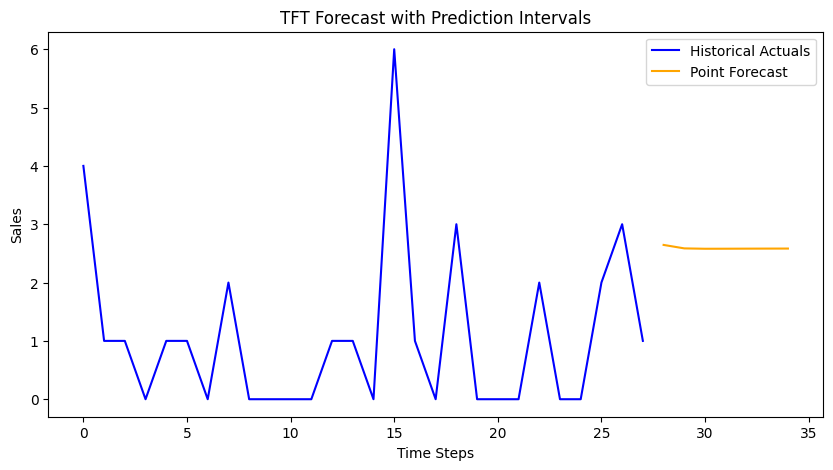

In [12]:
print("--- Plotting TFT Prediction Intervals Manually ---")

# 1. Generating predictions from the validation dataloader
predictions = tft.predict(val_dataloader, return_x=True)

# 2. Extracting actuals, predictions, and encoder values for the first validation sample (idx=0)
x, y = predictions.x, predictions.output

# Getting historical actuals (encoder) and future actuals (decoder target)
encoder_target = x["encoder_target"][0].cpu().numpy()
decoder_target = y[0].cpu().numpy() # If quantile loss is used, this contains quantiles or point estimates

# Setting up the timeline plot
plt.figure(figsize=(10, 5))
plt.plot(range(len(encoder_target)), encoder_target, label="Historical Actuals", color="blue")

# Plotting prediction (handling shape depending on whether it's quantile output or point forecast)
if decoder_target.ndim > 1:
    # If quantiles are present (e.g., P10, P50, P90)
    median_pred = decoder_target[:, 1] # Median (P50)
    p10_pred = decoder_target[:, 0]    # Lower bound (P10)
    p90_pred = decoder_target[:, 2]    # Upper bound (P90)

    future_steps = range(len(encoder_target), len(encoder_target) + len(median_pred))

    plt.plot(future_steps, median_pred, label="Predicted Median (P50)", color="orange")
    plt.fill_between(future_steps, p10_pred, p90_pred, color="orange", alpha=0.3, label="Prediction Interval (P10-P90)")
else:
    future_steps = range(len(encoder_target), len(encoder_target) + len(decoder_target))
    plt.plot(future_steps, decoder_target, label="Point Forecast", color="orange")

plt.legend()
plt.title("TFT Forecast with Prediction Intervals")
plt.xlabel("Time Steps")
plt.ylabel("Sales")
plt.show()

OR Tools Inventory **Optimization**

In [13]:
print("--- Setting up OR-Tools Inventory Optimization ---")

# 1. Initializing the linear solver with the GLOP backend
solver = pywraplp.Solver.CreateSolver('GLOP')
if not solver:
    raise Exception("Could not create solver GLOP")

# 2. Defining parameters & cost weights for optimization
# (Using sample values for holding cost, stockout penalty, and storage limits)
holding_cost_per_unit = 0.5   # Cost to store 1 unit in inventory
stockout_cost_per_unit = 15.0 # Penalty cost if a unit runs out and fails demand
max_storage_capacity = 500    # Maximum warehouse storage space constraint

# Forecasted demand value from our models (e.g., 120 units expected)
forecasted_demand = 120.0
starting_inventory = 30.0

# 3. Decision Variables
# order_qty: How many units to order
# ending_inventory: Final inventory left over
# stockout_qty: Unmet demand shortage
order_qty = solver.NumVar(0.0, max_storage_capacity, 'order_qty')
ending_inventory = solver.NumVar(0.0, max_storage_capacity, 'ending_inventory')
stockout_qty = solver.NumVar(0.0, forecasted_demand, 'stockout_qty')

# 4. Constraints
# Constraint 1: Inventory balance equation -> Starting + Order - Demand = Ending - Shortage
# Rearranged: starting_inventory + order_qty - forecasted_demand == ending_inventory - stockout_qty
inventory_balance = solver.Constraint(starting_inventory - forecasted_demand, starting_inventory - forecasted_demand, 'inventory_balance')
inventory_balance.SetCoefficient(order_qty, 1.0)
inventory_balance.SetCoefficient(ending_inventory, -1.0)
inventory_balance.SetCoefficient(stockout_qty, 1.0)

# Constraint 2: Storage capacity constraint on ending inventory
storage_constraint = solver.Constraint(0.0, max_storage_capacity, 'storage_constraint')
storage_constraint.SetCoefficient(ending_inventory, 1.0)

# 5. Objective Function: Minimize (Holding Cost * Ending Inventory) + (Stockout Cost * Shortage)
objective = solver.Objective()
objective.SetCoefficient(ending_inventory, holding_cost_per_unit)
objective.SetCoefficient(stockout_qty, stockout_cost_per_unit)
objective.SetMinimization()

# 6. Solving the optimization problem
status = solver.Solve()

if status == pywraplp.Solver.OPTIMAL:
    print("\n--- Optimization Complete: Optimal Solution Found ---")
    print(f"Optimal Order Quantity : {order_qty.solution_value():.2f} units")
    print(f"Ending Inventory       : {ending_inventory.solution_value():.2f} units")
    print(f"Expected Stockout (Shortage): {stockout_qty.solution_value():.2f} units")
    print(f"Minimum Total Cost     : ${objective.Value():.2f}")
else:
    print("The solver could not find an optimal solution.")

--- Setting up OR-Tools Inventory Optimization ---

--- Optimization Complete: Optimal Solution Found ---
Optimal Order Quantity : 0.00 units
Ending Inventory       : 90.00 units
Expected Stockout (Shortage): 0.00 units
Minimum Total Cost     : $45.00


In [14]:
joblib.dump(lgb_model, 'lgb_dfio_model.pkl')

['lgb_dfio_model.pkl']